In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer

sns.set_theme(style="whitegrid")

In [13]:
%pip install pdfplumber

Note: you may need to restart the kernel to use updated packages.


In [19]:
import pandas as pd
import pdfplumber
import re

# PDF file location
file_path = "/Users/padideh/Documents/CICCC/ML/Week-4/wine_dataset.pdf"

# Column names
columns = [
    "alcohol",
    "malic_acid",
    "ash",
    "alcalinity_of_ash",
    "magnesium",
    "total_phenols",
    "flavanoids",
    "nonflavanoid_phenols",
    "proanthocyanins",
    "color_intensity",
    "hue",
    "od280/od315_of_diluted_wines",
    "proline",
    "target"
]

# Extract rows
data = []

with pdfplumber.open(file_path) as pdf:
    for page in pdf.pages:
        text = page.extract_text()

        for line in text.split("\n"):
            values = line.split()

            if len(values) == 14:
                try:
                    row = [float(value) for value in values]
                    data.append(row)
                except ValueError:
                    continue

# Create DataFrame
df = pd.DataFrame(data, columns=columns)

# Convert target to integer
df["target"] = df["target"].astype(int)

# Display dataset
display(df.head())

print("Dataset shape:", df.shape)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


Dataset shape: (178, 14)


In [22]:
df.shape;

In [23]:
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nTarget distribution:")
print(df["target"].value_counts().sort_index())

# Validate extraction
assert df.shape == (178, 14), "Check PDF extraction: unexpected dataset shape."
assert set(df["target"].unique()) == {0, 1, 2}, "Unexpected target classes."

Number of rows: 178
Number of columns: 14

Missing values:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64

Duplicate rows:
0

Target distribution:
target
0    59
1    71
2    48
Name: count, dtype: int64


In [24]:
# First five rows
display(df.head())

# Data types
df.info()

# Statistical summary
display(df.describe().T)

# Correlation matrix
display(df.drop(columns="target").corr())

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  target          

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
alcohol,1.000000,0.094397,0.211545,-0.310235,0.270798,0.289101,0.236815,-0.155929,0.136698,0.546364,-0.071747,0.072343,0.643720
malic_acid,0.094397,1.000000,0.164045,0.288500,-0.054575,-0.335167,-0.411007,0.292977,-0.220746,0.248985,-0.561296,-0.368710,-0.192011
ash,0.211545,0.164045,1.000000,0.443367,0.286587,0.128980,0.115077,0.186230,0.009652,0.258887,-0.074667,0.003911,0.223626
alcalinity_of_ash,-0.310235,0.288500,0.443367,1.000000,-0.083333,-0.321113,-0.351370,0.361922,-0.197327,0.018732,-0.273955,-0.276769,-0.440597
magnesium,0.270798,-0.054575,0.286587,-0.083333,1.000000,0.214401,0.195784,-0.256294,0.236441,0.199950,0.055398,0.066004,0.393351
total_phenols,0.289101,-0.335167,0.128980,-0.321113,0.214401,1.000000,0.864564,-0.449935,0.612413,-0.055136,0.433681,0.699949,0.498115
flavanoids,0.236815,-0.411007,0.115077,-0.351370,0.195784,0.864564,1.000000,-0.537900,0.652692,-0.172379,0.543479,0.787194,0.494193
nonflavanoid_phenols,-0.155929,0.292977,0.186230,0.361922,-0.256294,-0.449935,-0.537900,1.000000,-0.365845,0.139057,-0.262640,-0.503270,-0.311385
proanthocyanins,0.136698,-0.220746,0.009652,-0.197327,0.236441,0.612413,0.652692,-0.365845,1.000000,-0.025250,0.295544,0.519067,0.330417
color_intensity,0.546364,0.248985,0.258887,0.018732,0.199950,-0.055136,-0.172379,0.139057,-0.025250,1.000000,-0.521813,-0.428815,0.316100


In [25]:
#Save the extracted data as CSV (optional)
df.to_csv(
    "/Users/padideh/Documents/CICCC/ML/Week-4/wine_dataset_extracted.csv",
    index=False
)

print("CSV file saved successfully!")

CSV file saved successfully!


In [26]:
#Check missing values and duplicates
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["target"].value_counts().sort_index())

Missing values:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64

Duplicate rows: 0

Target distribution:
target
0    59
1    71
2    48
Name: count, dtype: int64


In [27]:
# Data cleaning
df_clean = df.copy()

df_clean.columns = df_clean.columns.str.strip()

feature_columns = df_clean.columns.drop("target")

df_clean[feature_columns] = df_clean[feature_columns].apply(
    pd.to_numeric, errors="coerce"
)

df_clean = df_clean.drop_duplicates()

df_clean = df_clean.dropna(subset=["target"])

df_clean["target"] = df_clean["target"].astype(int)

print("Clean dataset:", df_clean.shape)

Clean dataset: (178, 14)


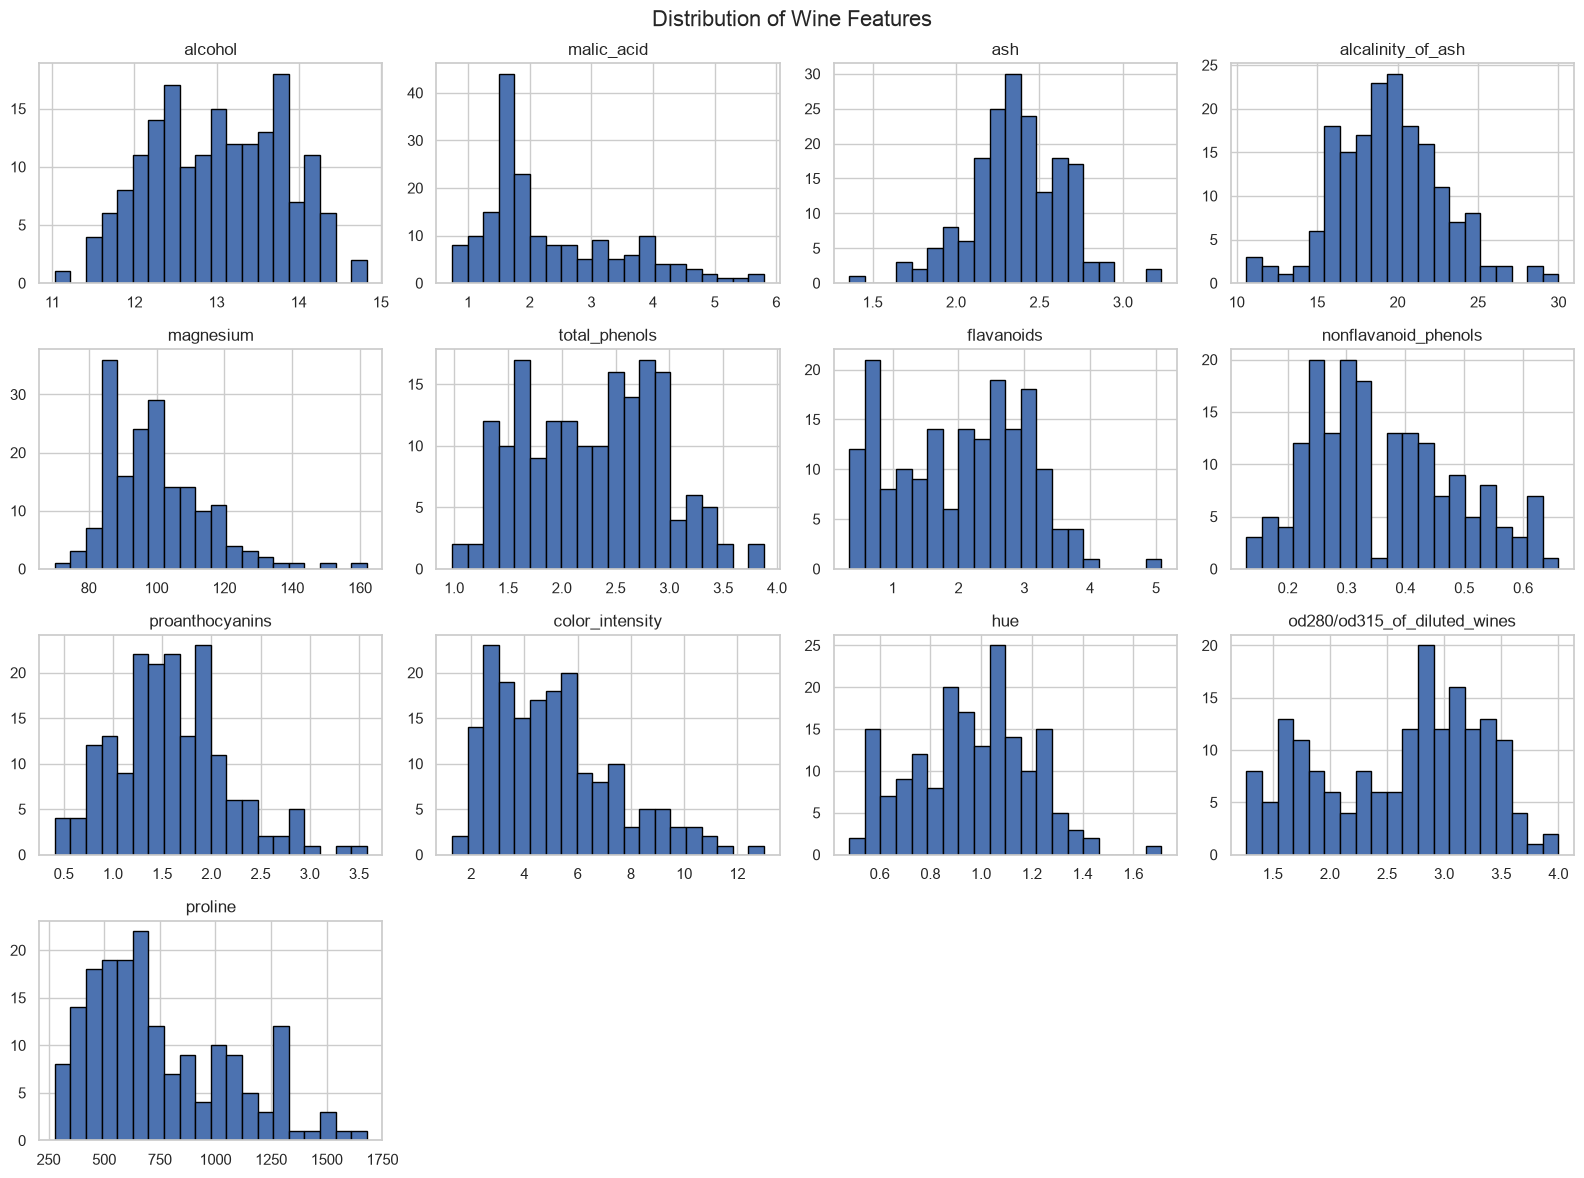

In [28]:
#EDA — Feature distributions
X_original = df_clean.drop(columns="target")
y = df_clean["target"]

X_original.hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Wine Features", fontsize=16)
plt.tight_layout()
plt.show()

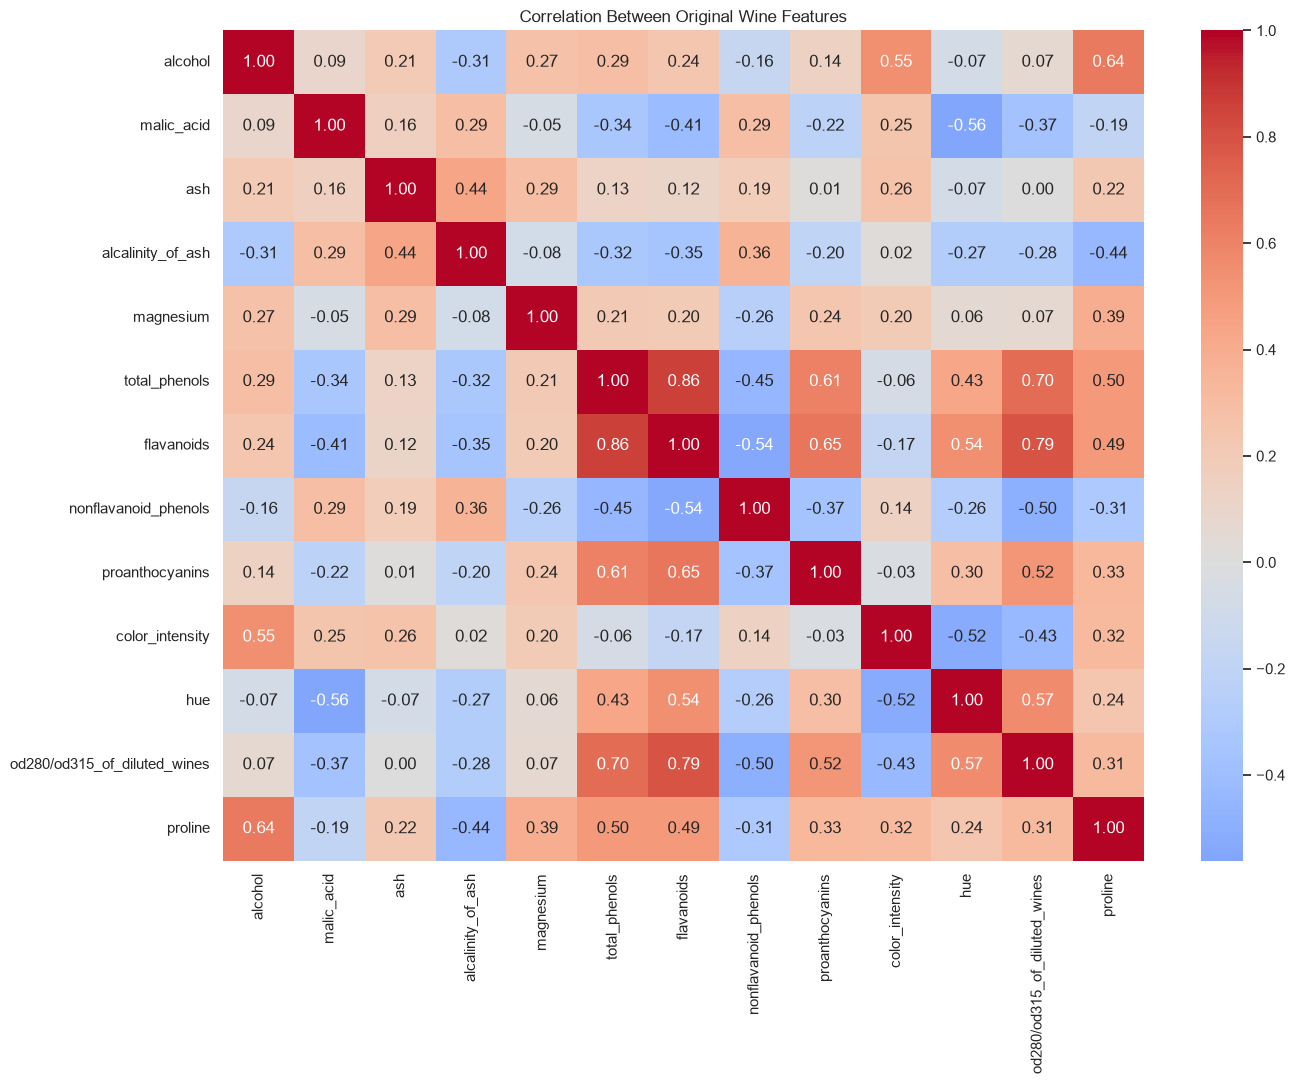

In [29]:
# EDA — Correlation heatmap
plt.figure(figsize=(14, 11))

corr_matrix = X_original.corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Between Original Wine Features")
plt.tight_layout()
plt.show()

In [30]:
#EDA — Find strongly correlated features
corr_abs = X_original.corr().abs()

upper_triangle = corr_abs.where(
    np.triu(
        np.ones(corr_abs.shape),
        k=1
    ).astype(bool)
)

strong_pairs = (
    upper_triangle
    .stack()
    .sort_values(ascending=False)
)

print("Strongest feature correlations:")
display(strong_pairs.head(15))

Strongest feature correlations:


total_phenols         flavanoids                      0.864564
flavanoids            od280/od315_of_diluted_wines    0.787194
total_phenols         od280/od315_of_diluted_wines    0.699949
flavanoids            proanthocyanins                 0.652692
alcohol               proline                         0.643720
total_phenols         proanthocyanins                 0.612413
hue                   od280/od315_of_diluted_wines    0.565468
malic_acid            hue                             0.561296
alcohol               color_intensity                 0.546364
flavanoids            hue                             0.543479
                      nonflavanoid_phenols            0.537900
color_intensity       hue                             0.521813
proanthocyanins       od280/od315_of_diluted_wines    0.519067
nonflavanoid_phenols  od280/od315_of_diluted_wines    0.503270
total_phenols         proline                         0.498115
dtype: float64

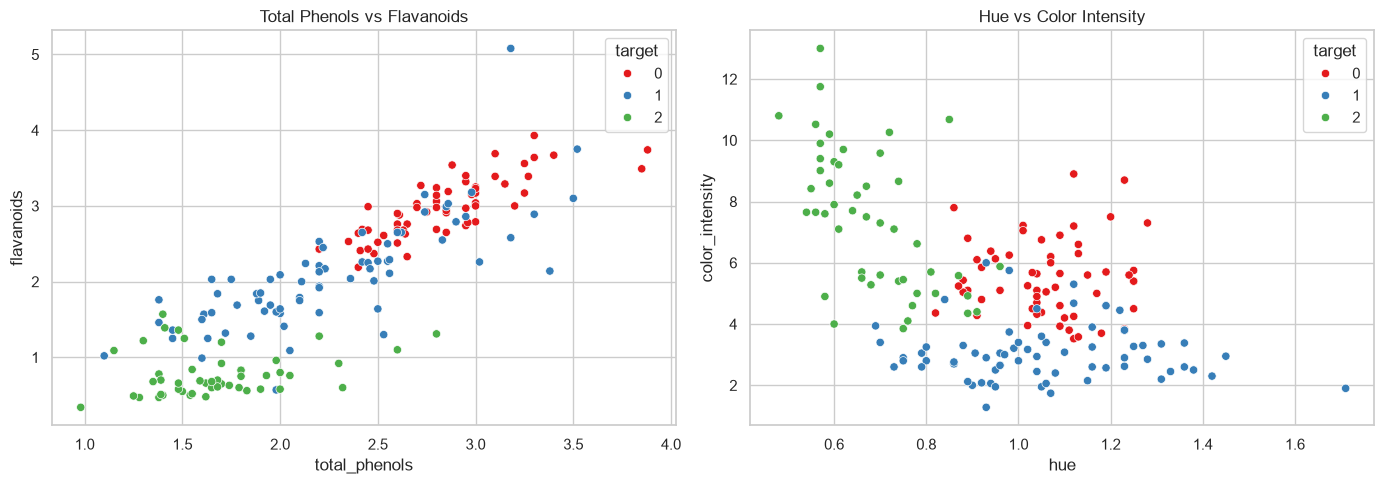

                 total_phenols  flavanoids  color_intensity       hue
total_phenols         1.000000    0.864564        -0.055136  0.433681
flavanoids            0.864564    1.000000        -0.172379  0.543479
color_intensity      -0.055136   -0.172379         1.000000 -0.521813
hue                   0.433681    0.543479        -0.521813  1.000000


In [31]:
# EDA — Examine candidate feature relationships
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=df_clean,
    x="total_phenols",
    y="flavanoids",
    hue="target",
    palette="Set1",
    ax=axes[0]
)

axes[0].set_title("Total Phenols vs Flavanoids")

sns.scatterplot(
    data=df_clean,
    x="hue",
    y="color_intensity",
    hue="target",
    palette="Set1",
    ax=axes[1]
)

axes[1].set_title("Hue vs Color Intensity")

plt.tight_layout()
plt.show()

print(
    X_original[
        ["total_phenols", "flavanoids",
         "color_intensity", "hue"]
    ].corr()
)

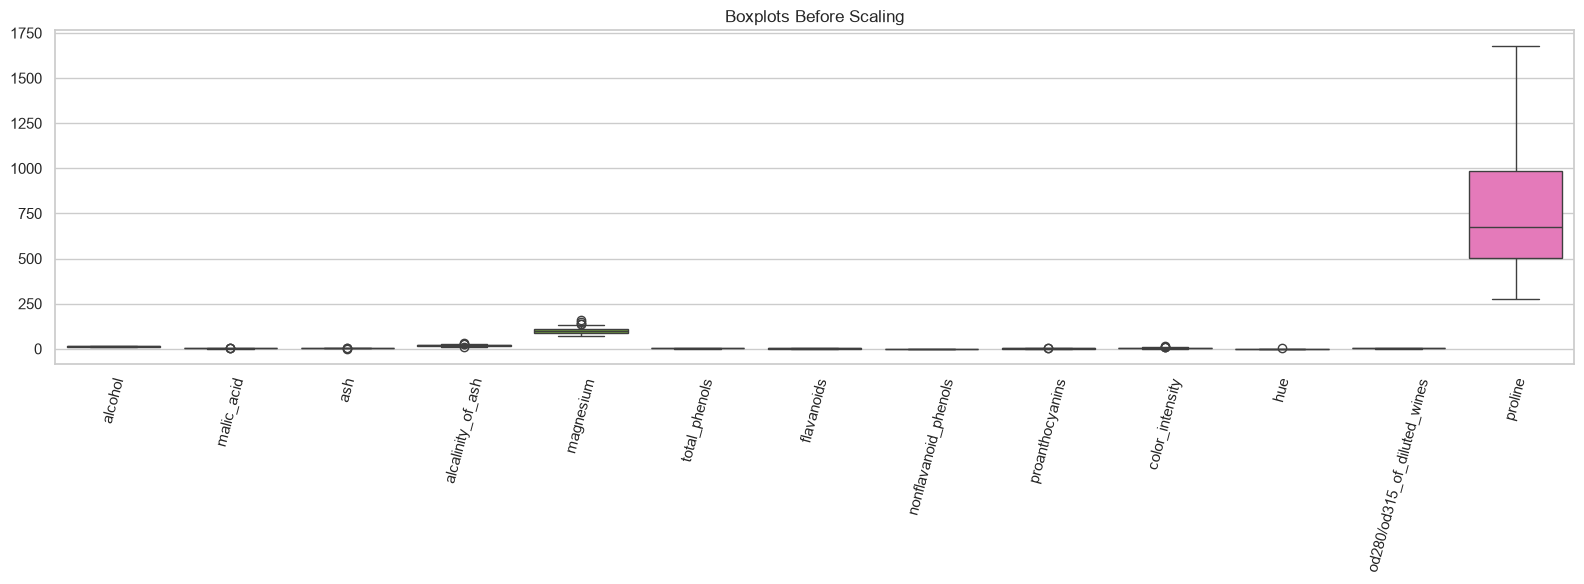

Potential outliers by feature:
alcalinity_of_ash               4
magnesium                       4
color_intensity                 4
malic_acid                      3
ash                             3
proanthocyanins                 2
hue                             1
alcohol                         0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64


In [32]:
# 9. EDA — Boxplots and IQR outliers
plt.figure(figsize=(16, 6))

sns.boxplot(data=X_original)

plt.xticks(rotation=75)
plt.title("Boxplots Before Scaling")
plt.tight_layout()
plt.show()


Q1 = X_original.quantile(0.25)
Q3 = X_original.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (X_original < lower_bound) |
    (X_original > upper_bound)
)

outlier_counts = outlier_mask.sum().sort_values(ascending=False)

print("Potential outliers by feature:")
print(outlier_counts)

In [34]:
# Feature engineering
def make_features(frame):

    result = frame.copy()

    result["phenols_plus_flavanoids"] = (
        result["total_phenols"] +
        result["flavanoids"]
    )

    result["flavanoids_to_phenols"] = (
        result["flavanoids"] /
        (result["total_phenols"] + 1e-6)
    )

    result["color_per_hue"] = (
        result["color_intensity"] /
        (result["hue"] + 1e-6)
    )

    return result


X_engineered = make_features(X_original)

print("Original features:", X_original.shape[1])
print("Engineered features:", X_engineered.shape[1])

display(
    X_engineered[
        [
            "phenols_plus_flavanoids",
            "flavanoids_to_phenols",
            "color_per_hue"
        ]
    ].head()
)

Original features: 13
Engineered features: 16


,phenols_plus_flavanoids,flavanoids_to_phenols,color_per_hue
0,5.86,1.092857,5.423072
1,5.41,1.041509,4.171425
2,6.04,1.157142,5.514558
3,7.34,0.906493,9.069757
4,5.49,0.960714,4.153842


,count,mean,std,min,25%,50%,75%,max
phenols_plus_flavanoids,178.0,4.324382,1.571734,1.320000,2.840000,4.405000,5.687500,8.260000
flavanoids_to_phenols,178.0,0.843691,0.282763,0.258621,0.622346,0.937715,1.056952,1.597484
color_per_hue,178.0,6.039042,4.346909,1.111110,3.140362,4.777029,6.694131,22.806978


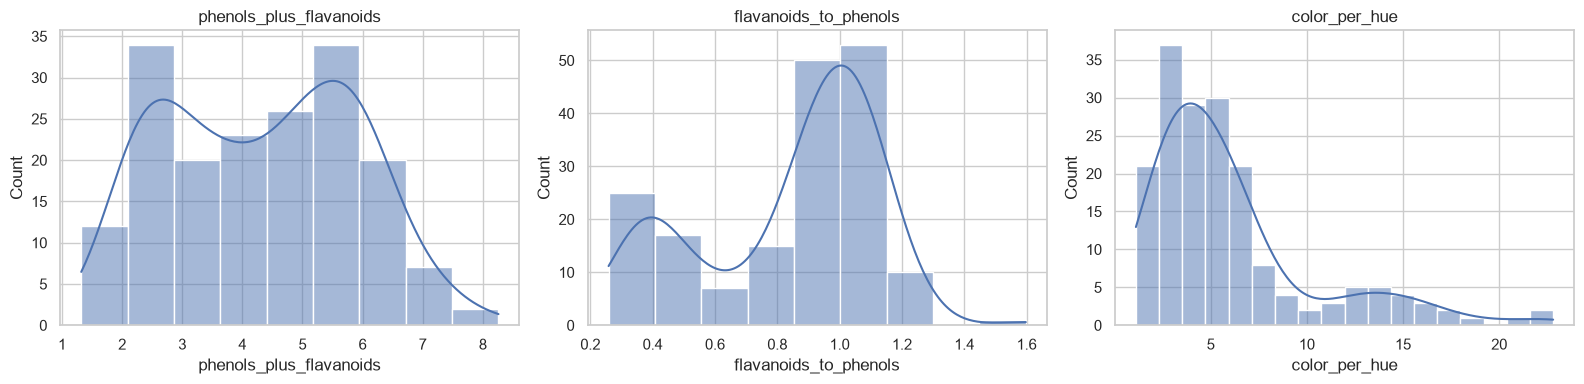

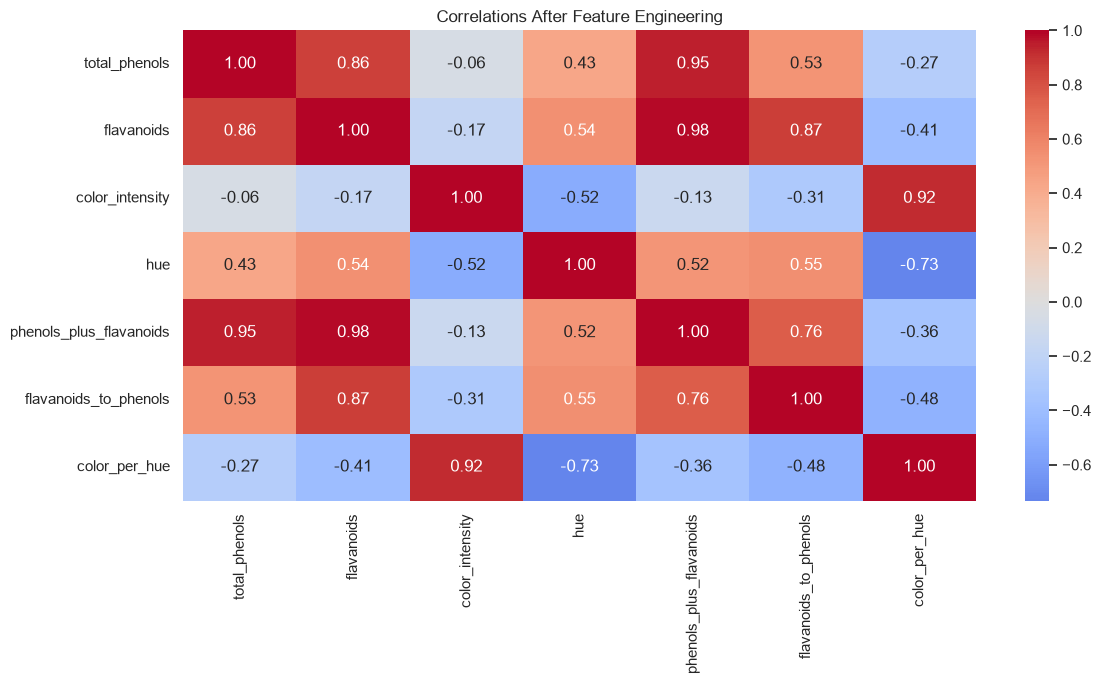

In [36]:
# EDA — Examine the engineered features
engineered_columns = [
    "phenols_plus_flavanoids",
    "flavanoids_to_phenols",
    "color_per_hue"
]

display(
    X_engineered[engineered_columns].describe().T
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, column in zip(axes, engineered_columns):

    sns.histplot(
        X_engineered[column],
        kde=True,
        ax=ax
    )

    ax.set_title(column)

plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 7))

sns.heatmap(
    X_engineered[
        [
            "total_phenols",
            "flavanoids",
            "color_intensity",
            "hue"
        ] + engineered_columns
    ].corr(),
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlations After Feature Engineering")
plt.tight_layout()
plt.show()


In [37]:
# Train/test split and preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X_engineered,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (133, 16)
Testing shape: (45, 16)


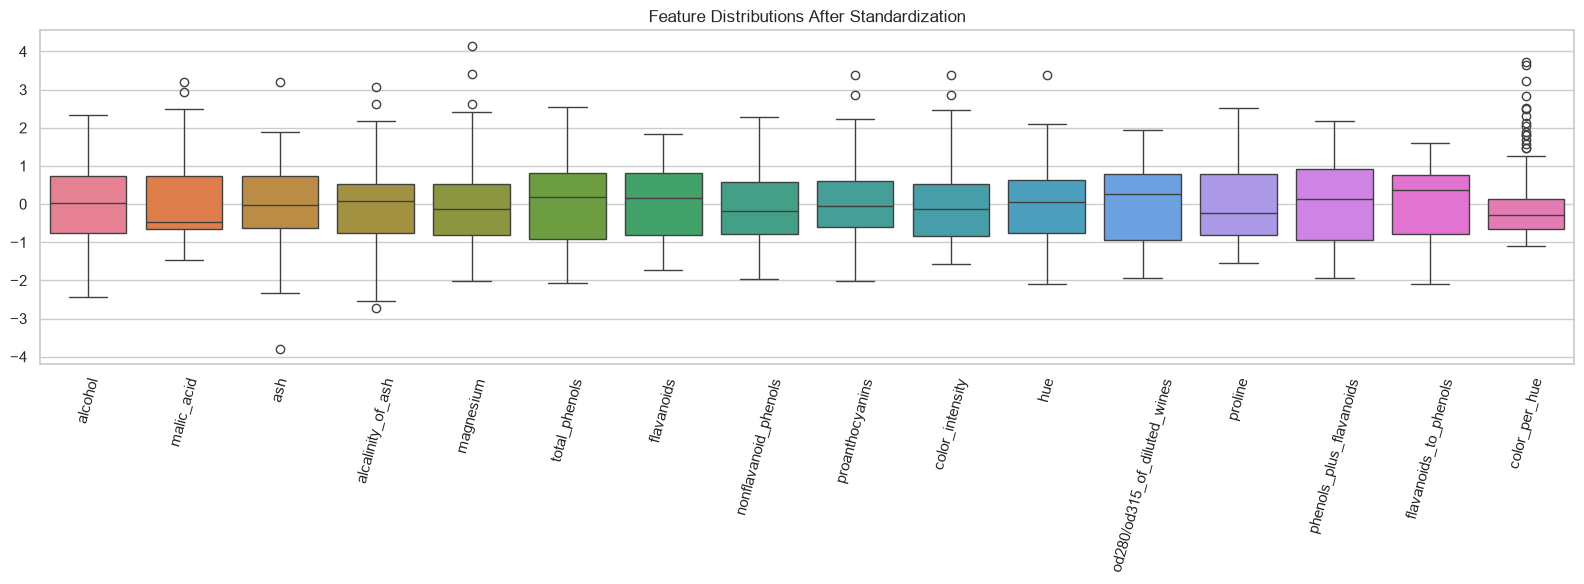

In [39]:
# EDA — Correlation after scaling
scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
)

plt.figure(figsize=(16, 6))

sns.boxplot(data=scaled_df)

plt.xticks(rotation=75)
plt.title("Feature Distributions After Standardization")
plt.tight_layout()
plt.show()

In [40]:
# Apply PCA and inspect explained variance
pca_full = PCA()

X_train_pca_full = pca_full.fit_transform(X_train_scaled)

explained_variance = pca_full.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance)

pca_summary = pd.DataFrame({
    "Component": [
        f"PC{i+1}"
        for i in range(len(explained_variance))
    ],
    "Explained Variance": explained_variance,
    "Cumulative Variance": cumulative_variance
})

display(pca_summary)

,Component,Explained Variance,Cumulative Variance
0,PC1,3.994594e-01,0.399459
1,PC2,1.896403e-01,0.589100
2,PC3,9.100718e-02,0.680107
3,PC4,6.361638e-02,0.743723
4,PC5,5.920574e-02,0.802929
5,PC6,4.905117e-02,0.851980
6,PC7,3.822084e-02,0.890201
7,PC8,3.027643e-02,0.920477
8,PC9,2.032653e-02,0.940804
9,PC10,1.777653e-02,0.958581


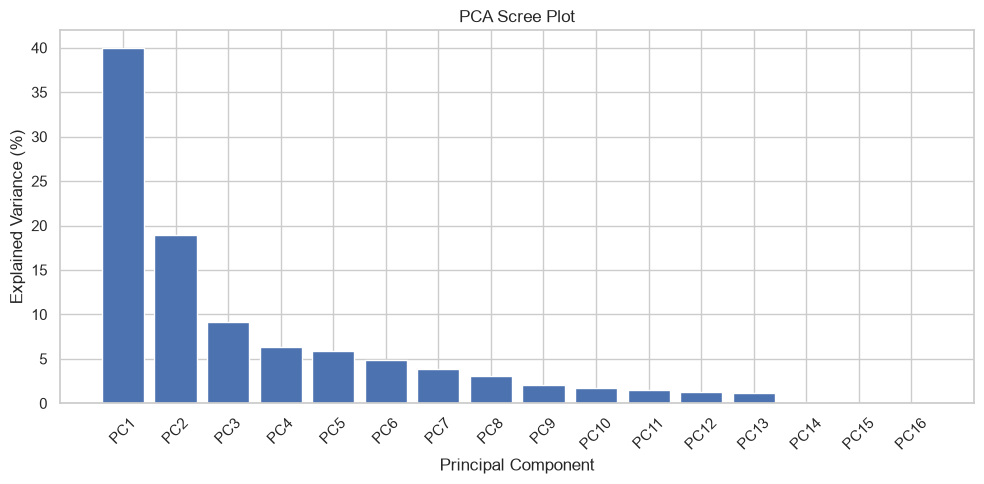

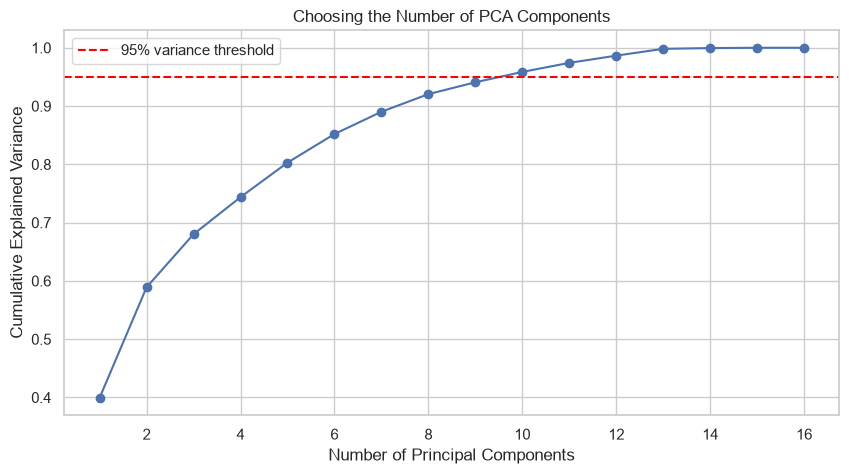

In [41]:
# Plot explained variance
plt.figure(figsize=(10, 5))

plt.bar(
    pca_summary["Component"],
    pca_summary["Explained Variance"] * 100
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Scree Plot")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.95,
    color="red",
    linestyle="--",
    label="95% variance threshold"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Choosing the Number of PCA Components")
plt.legend()
plt.grid(True)
plt.show()

In [42]:
#Apply PCA with 95% explained variance
pca_95 = PCA(n_components=0.95)

X_train_pca_95 = pca_95.fit_transform(X_train_scaled)

X_test_pca_95 = pca_95.transform(X_test_scaled)

print("Features before PCA:", X_train_scaled.shape[1])

print("Components after PCA:", pca_95.n_components_)

print(
    "Total variance retained:",
    round(pca_95.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Features before PCA: 16
Components after PCA: 10
Total variance retained: 95.86 %


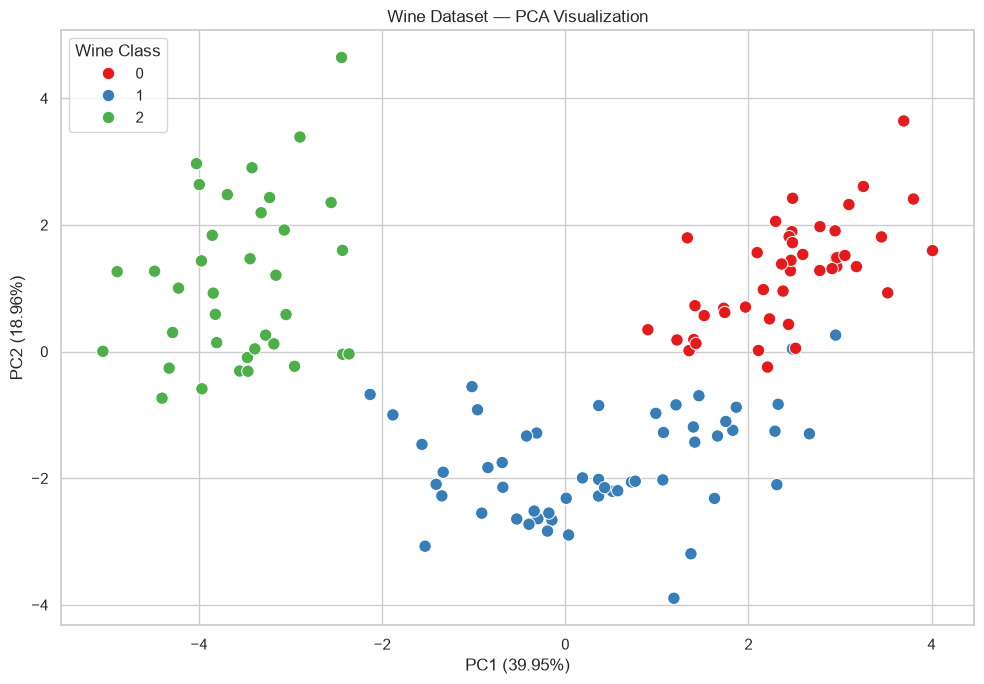

In [43]:
# Visualize PC1 and PC2
pca_2d = PCA(n_components=2)

X_train_pca_2d = pca_2d.fit_transform(X_train_scaled)

pca_df = pd.DataFrame(
    X_train_pca_2d,
    columns=["PC1", "PC2"]
)

pca_df["target"] = y_train.to_numpy()

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="target",
    palette="Set1",
    s=80
)

plt.xlabel(
    f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.2f}%)"
)

plt.ylabel(
    f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.2f}%)"
)

plt.title("Wine Dataset — PCA Visualization")
plt.legend(title="Wine Class")
plt.tight_layout()
plt.show()

PCA component weights:


,PC1,PC2
alcohol,0.091227,0.444527
malic_acid,-0.201168,0.119076
ash,-0.013397,0.256368
alcalinity_of_ash,-0.179827,-0.074364
magnesium,0.085440,0.259802
total_phenols,0.327409,0.142898
flavanoids,0.376014,0.072861
nonflavanoid_phenols,-0.230339,-0.047075
proanthocyanins,0.261681,0.077798
color_intensity,-0.130297,0.494425


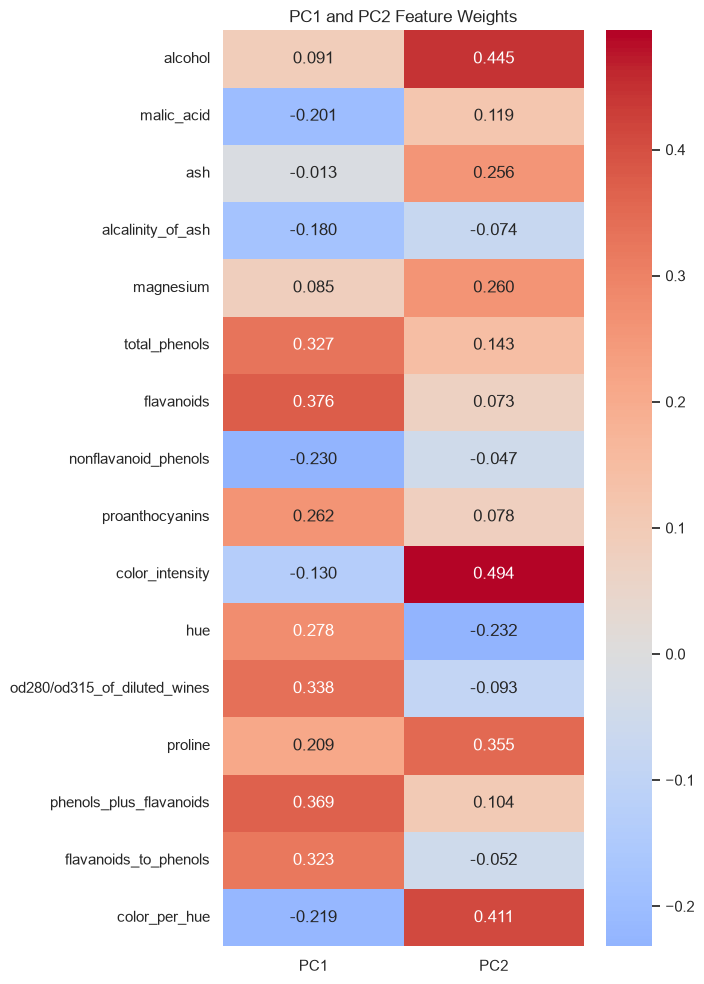

Largest absolute PC1 weights:


flavanoids                      0.376014
phenols_plus_flavanoids         0.369436
od280/od315_of_diluted_wines    0.337838
total_phenols                   0.327409
flavanoids_to_phenols           0.323251
hue                             0.278159
proanthocyanins                 0.261681
nonflavanoid_phenols            0.230339
color_per_hue                   0.219093
proline                         0.209321
malic_acid                      0.201168
alcalinity_of_ash               0.179827
color_intensity                 0.130297
alcohol                         0.091227
magnesium                       0.085440
ash                             0.013397
Name: PC1, dtype: float64

Largest absolute PC2 weights:


color_intensity                 0.494425
alcohol                         0.444527
color_per_hue                   0.411007
proline                         0.355197
magnesium                       0.259802
ash                             0.256368
hue                             0.231957
total_phenols                   0.142898
malic_acid                      0.119076
phenols_plus_flavanoids         0.104228
od280/od315_of_diluted_wines    0.092721
proanthocyanins                 0.077798
alcalinity_of_ash               0.074364
flavanoids                      0.072861
flavanoids_to_phenols           0.051533
nonflavanoid_phenols            0.047075
Name: PC2, dtype: float64

In [44]:
# Find which original and engineered features contribute to PC1 and PC2
loadings = pd.DataFrame(
    pca_2d.components_.T,
    index=X_engineered.columns,
    columns=["PC1", "PC2"]
)

print("PCA component weights:")
display(loadings)

plt.figure(figsize=(7, 10))

sns.heatmap(
    loadings,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".3f"
)

plt.title("PC1 and PC2 Feature Weights")
plt.tight_layout()
plt.show()


print("Largest absolute PC1 weights:")
display(
    loadings["PC1"].abs().sort_values(ascending=False)
)

print("Largest absolute PC2 weights:")
display(
    loadings["PC2"].abs().sort_values(ascending=False)
)


In [45]:
# Compare PCA with and without Feature Engineering
datasets = {
    "Original 13 Features": X_original,
    "Engineered 16 Features": X_engineered
}

comparison = []

for name, features in datasets.items():

    train_features, test_features = train_test_split(
        features,
        test_size=0.25,
        random_state=42,
        stratify=y
    )

    imputer = SimpleImputer(strategy="median")

    train_imputed = imputer.fit_transform(train_features)

    scaler = StandardScaler()

    train_scaled = scaler.fit_transform(train_imputed)

    model = PCA(n_components=0.95)

    model.fit(train_scaled)

    comparison.append({
        "Dataset": name,
        "Input Features": train_scaled.shape[1],
        "PCA Components": model.n_components_,
        "Variance Retained (%)":
            model.explained_variance_ratio_.sum() * 100
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(2))

,Dataset,Input Features,PCA Components,Variance Retained (%)
0,Original 13 Features,13,10,96.37
1,Engineered 16 Features,16,10,95.86
